# Logistic Regression
- In this notebook logistic regression is implemented to two different dataset.

In [124]:
import numpy as np
import matplotlib.pyplot as plt
from utils import *
import math
import copy
%matplotlib inline

## Logistic Regression model
- to predict whether a student gets admitted into a university.

### Problem Statement  
The administrator of a university department want to determine each applicant's chance of admission based on their results two examns.
- We have historical data from previous applicants that we can use as a training set for logistic regression.
- For each training example we have the applicant's score on two exams and the admission decision.
- Our task is to build a classification model that estimates an applicant's probability of admission based on the scores from those two exams.


#### Loading and visualizing the data

In [125]:
# load dataset
X_train, y_train = load_data(r"C:\Machine Learning\Coursera\Supervised ML (Regression and Classification)\03_Classification\ex2data1.txt")
# X_train contains exam score on two exams
# y_train is the admission decision
# y_train = 1 is student was admitted
# y_train = 0 is student was not admitted
# both are numpy arrays

In [126]:
# view the variables
print("first five elements of X_train are:\n", X_train[:5])
print("Type of X_train:",type(X_train))

first five elements of X_train are:
 [[34.62365962 78.02469282]
 [30.28671077 43.89499752]
 [35.84740877 72.90219803]
 [60.18259939 86.3085521 ]
 [79.03273605 75.34437644]]
Type of X_train: <class 'numpy.ndarray'>


In [127]:
print("first five elements of y_train ara:\n", y_train[:5])
print("type of y_train:", type(y_train))

first five elements of y_train ara:
 [0. 0. 0. 1. 1.]
type of y_train: <class 'numpy.ndarray'>


In [128]:
# Checking the dimensions of variables
print("The shape of X_train is:" + str(X_train.shape))
print("The shape of y_train is:" + str(y_train.shape))
print("we have m = %d training examples" % len(y_train))

The shape of X_train is:(100, 2)
The shape of y_train is:(100,)
we have m = 100 training examples


##### Visualizing our data
- Before starting to implement any learning alogrithm, it is always good to visualize the data if possible.

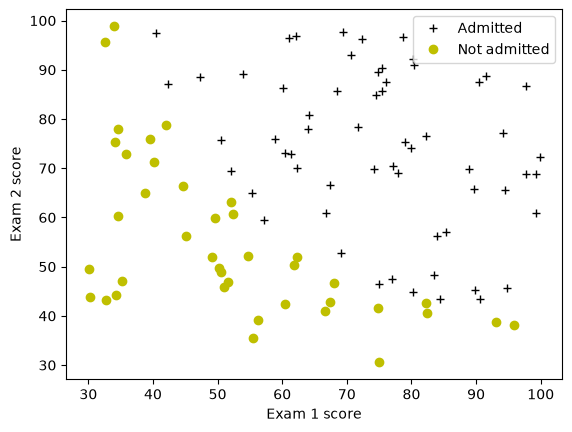

In [129]:
plot_data(X_train,y_train[:],pos_label="Admitted",neg_label="Not admitted")

plt.ylabel("Exam 2 score")
plt.xlabel("Exam 1 score")
plt.legend(loc="upper right")
plt.show()

#### Sigmoid function

In [130]:
def sigmoid(z):
    g = (1)/(1 + np.e**(-z))

    return g

In [131]:
value = 0

print (f"sigmoid({value}) = {sigmoid(value)}")

sigmoid(0) = 0.5


#### Cost function for logistic regression

In [132]:
def compute_cost(X,y,w,b):
    m,n = X.shape

    cost = 0
    for i in range(m):
        f_wb_i = sigmoid(np.dot(X[i],w) + b)
        cost += (-y[i]*np.log(f_wb_i)-(1-y[i])*np.log(1-f_wb_i))
    total_cost = cost/m

    return total_cost

In [133]:
m, n = X_train.shape

# Compute and display cost with w and b initialized to zeros
initial_w = np.zeros(n)
initial_b = 0.
cost = compute_cost(X_train, y_train, initial_w, initial_b)
print('Cost at initial w and b (zeros): {:.3f}'.format(cost))

Cost at initial w and b (zeros): 0.693


#### Gradient for logistic regression

In [134]:
def compute_gradient(X,y,w,b):
    m,n = X.shape
    dj_dw = np.zeros(n)
    dj_db = 0.

    for i in range(m):
        f_wb_i = sigmoid(np.dot(X[i],w) + b)
        error = f_wb_i - y[i]

        dj_db += error

        for j in range(n):
            dj_dw_ij = error * X[i,j]
            dj_dw[j] += dj_dw_ij

    dj_db /= m
    dj_dw /= m

    return dj_db,dj_dw

In [135]:
initial_w = np.zeros(n)
initial_b = 0.

dj_db, dj_dw = compute_gradient(X_train, y_train, initial_w, initial_b)
print(f'dj_db at initial w and b (zeros):{dj_db}' )
print(f'dj_dw at initial w and b (zeros):{dj_dw.tolist()}' )

dj_db at initial w and b (zeros):-0.1
dj_dw at initial w and b (zeros):[-12.00921658929115, -11.262842205513591]


In [136]:
# Compute and display cost and gradient with non-zero w and b
test_w = np.array([ 0.2, -0.5])
test_b = -24
dj_db, dj_dw  = compute_gradient(X_train, y_train, test_w, test_b)

print('dj_db at test w and b:', dj_db)
print('dj_dw at test w and b:', dj_dw.tolist())

dj_db at test w and b: -0.5999999999991071
dj_dw at test w and b: [-44.831353617873795, -44.37384124953978]


#### Gradient Descent

In [137]:
def gradient_descent(X,y,w_in,b_in,cost_function,gradient_function,alpha,num_iters):
    m = X.shape[0]
    j_history = []
    w_history = []

    for i in range(num_iters):
        dj_db,dj_dw = gradient_function(X,y,w_in,b_in)

        w_in = w_in - alpha*dj_dw
        b_in = b_in - alpha*dj_db

        if i < 100000:
            cost = compute_cost(X,y,w_in,b_in)
            j_history.append(cost)

        if i % math.ceil(num_iters/10) == 0 or i == (num_iters - 1):
            w_history.append(w_in)
            print(f"Iteration {i:4}, Cost {j_history[-1]:8.2f}")

    return w_in, b_in, j_history, w_history

In [138]:
np.random.seed(1)
initial_w = 0.01 * (np.random.rand(2) - 0.5)
initial_b = -8

# Some gradient descent settings
iterations = 10000
alpha = 0.001

w,b, J_history,_ = gradient_descent(X_train ,y_train, initial_w, initial_b, 
                                   compute_cost, compute_gradient, alpha, iterations)

Iteration    0, Cost     0.96


Iteration 1000, Cost     0.31
Iteration 2000, Cost     0.30
Iteration 3000, Cost     0.30
Iteration 4000, Cost     0.30
Iteration 5000, Cost     0.30
Iteration 6000, Cost     0.30
Iteration 7000, Cost     0.30
Iteration 8000, Cost     0.30
Iteration 9000, Cost     0.30
Iteration 9999, Cost     0.30
